# Machine Learning Assignment 2 — Question 1
## Decision-tree baseline and bagging from scratch

This notebook implements Q1(a)–(d) for the Olivetti Faces dataset. It is designed to run in Google Colab or a local Jupyter notebook. **Run all cells from top to bottom** to obtain the measured results, tables, plots, and saved artifacts.

- Roll number used: `m24ma2007`
- Seed: `242007` (all numeric characters, in order)
- Dataset: 400 images, 40 identities, 10 images per identity, 64 × 64 pixels
- Features: raw flattened pixels only (4,096 features); no PCA or other dimensionality reduction
- Per-identity split: 6 train, 2 validation, 2 test
- The split is generated once, saved to disk, and reused throughout.
- Models are trained only on clean training images. The masked test set is used only for evaluation.

**Important:** All numerical results are generated by running the experiment. Do not report placeholder or unexecuted results as measured findings.

## 0. Environment and imports

If running in Google Colab, the required packages are usually preinstalled. If needed, uncomment the installation line.

In [1]:
# If needed in a fresh environment:
# %pip install -q numpy pandas matplotlib scikit-learn

import os
import json
import time
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_olivetti_faces
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from IPython.display import display

ROLL_NUMBER = "m24ma2007"
SEED = int("".join(ch for ch in ROLL_NUMBER if ch.isdigit()))
assert SEED == 242007
RNG = np.random.default_rng(SEED)

OUT_DIR = "q1_outputs"
os.makedirs(OUT_DIR, exist_ok=True)

print("Roll number:", ROLL_NUMBER)
print("Seed:", SEED)
print("Output directory:", os.path.abspath(OUT_DIR))

Roll number: m24ma2007
Seed: 242007
Output directory: /home/M24MA2009/pawanassign/q1_outputs


## 1. Load data and create the fixed split

The random generator is seeded using the digits of the complete roll number. For each identity, shuffle its ten image indices and allocate 6/2/2 to train/validation/test. The split indices are saved and reused; do not regenerate them between experiments.

In [2]:
faces = fetch_olivetti_faces(shuffle=False)
X_images = faces.images.astype(np.float32)
y = faces.target.astype(np.int64)

assert X_images.shape == (400, 64, 64), X_images.shape
assert y.shape == (400,), y.shape
assert len(np.unique(y)) == 40
assert all(np.sum(y == identity) == 10 for identity in np.unique(y))

# Raw flattened pixels only: 64*64 = 4096 features.
X = X_images.reshape(len(X_images), -1)
assert X.shape == (400, 4096)

# Reproducible split: 6 train, 2 validation, 2 test per identity.
split_rng = np.random.default_rng(SEED)
train_idx, val_idx, test_idx = [], [], []
for identity in sorted(np.unique(y)):
    identity_idx = np.flatnonzero(y == identity)
    shuffled = split_rng.permutation(identity_idx)
    train_idx.extend(shuffled[:6].tolist())
    val_idx.extend(shuffled[6:8].tolist())
    test_idx.extend(shuffled[8:10].tolist())

train_idx = np.asarray(train_idx, dtype=np.int64)
val_idx = np.asarray(val_idx, dtype=np.int64)
test_idx = np.asarray(test_idx, dtype=np.int64)

# Check sizes and disjointness.
assert len(train_idx) == 240 and len(val_idx) == 80 and len(test_idx) == 80
assert len(set(train_idx) & set(val_idx)) == 0
assert len(set(train_idx) & set(test_idx)) == 0
assert len(set(val_idx) & set(test_idx)) == 0
for identity in np.unique(y):
    assert np.sum(y[train_idx] == identity) == 6
    assert np.sum(y[val_idx] == identity) == 2
    assert np.sum(y[test_idx] == identity) == 2

split_path = os.path.join(OUT_DIR, "olivetti_split_seed_242007.npz")
np.savez_compressed(
    split_path,
    train_idx=train_idx,
    val_idx=val_idx,
    test_idx=test_idx,
    seed=np.asarray(SEED),
    roll_number=np.asarray(ROLL_NUMBER)
)
split_metadata = {
    "roll_number": ROLL_NUMBER,
    "seed": SEED,
    "dataset": "sklearn.datasets.fetch_olivetti_faces",
    "feature_representation": "raw flattened 64x64 pixels; 4096 features",
    "train_per_identity": 6,
    "validation_per_identity": 2,
    "test_per_identity": 2,
    "train_count": int(len(train_idx)),
    "validation_count": int(len(val_idx)),
    "test_count": int(len(test_idx))
}
with open(os.path.join(OUT_DIR, "split_metadata.json"), "w", encoding="utf-8") as f:
    json.dump(split_metadata, f, indent=2)

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]

# Masked test data: centred 16x16 block, rows and columns 24..39 inclusive, set to zero.
X_images_masked = X_images.copy()
X_images_masked[:, 24:40, 24:40] = 0.0
X_masked = X_images_masked.reshape(len(X_images_masked), -1)
X_test_masked = X_masked[test_idx]

print("Images:", X_images.shape)
print("Flattened data:", X.shape)
print("Train/validation/test:", X_train.shape, X_val.shape, X_test.shape)
print("Saved split:", split_path)
print("Split is balanced: 6/2/2 images per identity.")


Images: (400, 64, 64)
Flattened data: (400, 4096)
Train/validation/test: (240, 4096) (80, 4096) (80, 4096)
Saved split: q1_outputs/olivetti_split_seed_242007.npz
Split is balanced: 6/2/2 images per identity.


## 2. Q1(a): tune and freeze one decision tree

Evaluate all 15 combinations of `max_depth ∈ {2, 4, 8, 16, None}` and `min_samples_leaf ∈ {1, 2, 4}`. Select the model using **validation accuracy only**. Ties are broken deterministically by the order in the grid below. After selection, freeze the setting and do not tune it again.

In [3]:
depth_grid = [2, 4, 8, 16, None]
leaf_grid = [1, 2, 4]
tree_grid_rows = []

for depth in depth_grid:
    for min_leaf in leaf_grid:
        clf = DecisionTreeClassifier(
            max_depth=depth,
            min_samples_leaf=min_leaf,
            random_state=SEED
        )
        clf.fit(X_train, y_train)
        tree_grid_rows.append({
            "max_depth": depth if depth is not None else "None",
            "min_samples_leaf": min_leaf,
            "train_accuracy": accuracy_score(y_train, clf.predict(X_train)),
            "validation_accuracy": accuracy_score(y_val, clf.predict(X_val))
        })

tree_grid = pd.DataFrame(tree_grid_rows)
display(tree_grid)
tree_grid.to_csv(os.path.join(OUT_DIR, "q1a_tree_grid.csv"), index=False)

# Stable tie-break: first configuration in the stated grid with maximum validation accuracy.
best_row_idx = int(np.argmax(tree_grid["validation_accuracy"].to_numpy()))
best_row = tree_grid.iloc[best_row_idx]
BEST_DEPTH = None if best_row["max_depth"] == "None" else int(best_row["max_depth"])
BEST_MIN_LEAF = int(best_row["min_samples_leaf"])

tree = DecisionTreeClassifier(
    max_depth=BEST_DEPTH,
    min_samples_leaf=BEST_MIN_LEAF,
    random_state=SEED
)
tree.fit(X_train, y_train)

def accuracy_triplet(model):
    return {
        "train_accuracy": accuracy_score(y_train, model.predict(X_train)),
        "validation_accuracy": accuracy_score(y_val, model.predict(X_val)),
        "test_accuracy": accuracy_score(y_test, model.predict(X_test))
    }

def tree_leaf_statistics(model, X_fit):
    leaf_ids = model.apply(X_fit)
    _, counts = np.unique(leaf_ids, return_counts=True)
    return {
        "number_of_leaves": int(model.get_n_leaves()),
        "mean_samples_per_leaf": float(np.mean(counts)),
        "fraction_singleton_leaves": float(np.mean(counts == 1))
    }

baseline_metrics = accuracy_triplet(tree)
baseline_leaf_stats = tree_leaf_statistics(tree, X_train)
baseline_row = {
    "selected_max_depth": BEST_DEPTH if BEST_DEPTH is not None else "None",
    "selected_min_samples_leaf": BEST_MIN_LEAF,
    **baseline_metrics,
    **baseline_leaf_stats
}
baseline_df = pd.DataFrame([baseline_row])
display(baseline_df)
baseline_df.to_csv(os.path.join(OUT_DIR, "q1a_selected_tree_metrics.csv"), index=False)

print("Frozen tree setting:", {"max_depth": BEST_DEPTH, "min_samples_leaf": BEST_MIN_LEAF})


,max_depth,min_samples_leaf,train_accuracy,validation_accuracy
0,2,1,0.075000,0.0625
1,2,2,0.075000,0.0625
2,2,4,0.075000,0.0625
3,4,1,0.150000,0.1000
4,4,2,0.150000,0.1000
5,4,4,0.150000,0.1000
6,8,1,0.250000,0.1500
7,8,2,0.250000,0.1500
8,8,4,0.250000,0.1500
9,16,1,0.450000,0.2375


,selected_max_depth,selected_min_samples_leaf,train_accuracy,validation_accuracy,test_accuracy,number_of_leaves,mean_samples_per_leaf,fraction_singleton_leaves
0,None,1,1.0,0.4625,0.6625,41,5.853659,0.02439


Frozen tree setting: {'max_depth': None, 'min_samples_leaf': 1}


### Interpreting depth and leaf occupancy

Use the measured grid and leaf statistics above when writing your discussion. Typically, increasing depth permits more complex partitions and can increase training accuracy, while validation/test accuracy may plateau or decline. This is an interpretation to check against your actual results, not a substitute for them. A singleton leaf contains exactly one of the 240 training examples.

## 3. Q1(b): implement bagging manually

Each tree is trained on a bootstrap sample of size 240 drawn with replacement from the original 240 training examples. The frozen tree hyperparameters from Q1(a) are reused. The implementation below does not use `sklearn.ensemble.BaggingClassifier`.

For each ensemble size `B`, the ensemble consists of the first `B` trees from one reproducibly generated sequence. Majority vote is used for the predicted class; the winning vote fraction is also retained as confidence.

In [4]:
B_VALUES = [1, 5, 10, 25, 50, 100, 200]
MAX_B = max(B_VALUES)
n_train = len(X_train)
classes = np.unique(y_train)

bag_rng = np.random.default_rng(SEED + 1)
bag_trees = []
bag_bootstrap_indices = []
bag_oob_masks = []
bag_fit_seconds = []

for b in range(MAX_B):
    boot_idx = bag_rng.integers(0, n_train, size=n_train)
    oob_mask = np.ones(n_train, dtype=bool)
    oob_mask[np.unique(boot_idx)] = False

    estimator = DecisionTreeClassifier(
        max_depth=BEST_DEPTH,
        min_samples_leaf=BEST_MIN_LEAF,
        random_state=SEED + 1000 + b
    )
    start = time.perf_counter()
    estimator.fit(X_train[boot_idx], y_train[boot_idx])
    elapsed = time.perf_counter() - start

    bag_trees.append(estimator)
    bag_bootstrap_indices.append(boot_idx)
    bag_oob_masks.append(oob_mask)
    bag_fit_seconds.append(elapsed)

def vote_matrix(models, X_eval, classes):
    """Return integer class-vote counts, with columns ordered as `classes`."""
    class_to_col = {c: i for i, c in enumerate(classes)}
    votes = np.zeros((len(X_eval), len(classes)), dtype=np.int32)
    for model in models:
        pred = model.predict(X_eval)
        for c in np.unique(pred):
            votes[pred == c, class_to_col[c]] += 1
    return votes

def summarize_votes(votes, classes):
    totals = votes.sum(axis=1)
    # argmax gives deterministic tie-breaking by class order.
    pred = classes[np.argmax(votes, axis=1)]
    sorted_votes = np.sort(votes, axis=1)
    winning = sorted_votes[:, -1]
    runner_up = sorted_votes[:, -2] if votes.shape[1] > 1 else np.zeros(len(votes))
    confidence = np.divide(winning, totals, out=np.zeros_like(winning, dtype=float), where=totals > 0)
    margin = np.divide(winning - runner_up, totals, out=np.zeros_like(winning, dtype=float), where=totals > 0)
    return pred, confidence, margin

bagging_rows = []
oob_rows = []
disagreement_rows = []
margin_rows = []
distinct_counts = []

for B in B_VALUES:
    models = bag_trees[:B]
    train_votes = vote_matrix(models, X_train, classes)
    val_votes = vote_matrix(models, X_val, classes)
    test_votes = vote_matrix(models, X_test, classes)

    pred_train, conf_train, margin_train = summarize_votes(train_votes, classes)
    pred_val, conf_val, margin_val = summarize_votes(val_votes, classes)
    pred_test, conf_test, margin_test = summarize_votes(test_votes, classes)

    distinct = [len(np.unique(idx)) for idx in bag_bootstrap_indices[:B]]
    distinct_counts.extend(distinct)

    bagging_rows.append({
        "B": B,
        "train_accuracy": accuracy_score(y_train, pred_train),
        "validation_accuracy": accuracy_score(y_val, pred_val),
        "test_accuracy": accuracy_score(y_test, pred_test),
        "mean_distinct_examples": float(np.mean(distinct)),
        "theoretical_expected_distinct": float(n_train * (1 - (1 - 1/n_train)**n_train)),
        "mean_train_winning_vote_fraction": float(np.mean(conf_train)),
        "mean_test_winning_vote_fraction": float(np.mean(conf_test)),
        "mean_test_vote_margin": float(np.mean(margin_test))
    })

    # OOB predictions for each training sample use only trees whose bootstrap omitted it.
    oob_votes = np.zeros((n_train, len(classes)), dtype=np.int32)
    for model, oob_mask in zip(models, bag_oob_masks[:B]):
        oob_ids = np.flatnonzero(oob_mask)
        if len(oob_ids) == 0:
            continue
        oob_pred = model.predict(X_train[oob_ids])
        class_to_col = {c: i for i, c in enumerate(classes)}
        for c in np.unique(oob_pred):
            oob_votes[oob_ids[oob_pred == c], class_to_col[c]] += 1
    has_oob = oob_votes.sum(axis=1) > 0
    oob_pred, _, _ = summarize_votes(oob_votes[has_oob], classes)
    oob_acc = accuracy_score(y_train[has_oob], oob_pred) if np.any(has_oob) else np.nan
    oob_rows.append({"B": B, "oob_accuracy": oob_acc, "training_samples_with_oob_vote": int(has_oob.sum())})

    # Mean pairwise disagreement: fraction of examples on which each pair of trees differs,
    # averaged over all tree pairs and validation examples.
    val_tree_preds = np.vstack([m.predict(X_val) for m in models])
    if B >= 2:
        pair_disagreements = [
            np.mean(val_tree_preds[i] != val_tree_preds[j])
            for i, j in itertools.combinations(range(B), 2)
        ]
        mean_disagreement = float(np.mean(pair_disagreements))
    else:
        mean_disagreement = 0.0
    disagreement_rows.append({"B": B, "mean_pairwise_disagreement": mean_disagreement})

    # Mean vote margin on validation examples (winning fraction minus runner-up fraction).
    margin_rows.append({"B": B, "mean_validation_vote_margin": float(np.mean(margin_val))})

bagging_metrics = pd.DataFrame(bagging_rows)
oob_metrics = pd.DataFrame(oob_rows)
disagreement_metrics = pd.DataFrame(disagreement_rows)
margin_metrics = pd.DataFrame(margin_rows)

bagging_metrics.to_csv(os.path.join(OUT_DIR, "q1b_bagging_metrics.csv"), index=False)
oob_metrics.to_csv(os.path.join(OUT_DIR, "q1c_oob_metrics.csv"), index=False)
disagreement_metrics.to_csv(os.path.join(OUT_DIR, "q1c_disagreement_metrics.csv"), index=False)
margin_metrics.to_csv(os.path.join(OUT_DIR, "q1c_vote_margin_metrics.csv"), index=False)

display(bagging_metrics)
display(oob_metrics)


,B,train_accuracy,validation_accuracy,test_accuracy,mean_distinct_examples,theoretical_expected_distinct,mean_train_winning_vote_fraction,mean_test_winning_vote_fraction,mean_test_vote_margin
0,1,0.737500,0.3000,0.3750,151.000,151.893194,1.000000,1.000000,1.000000
1,5,0.966667,0.4500,0.5125,152.200,151.893194,0.743333,0.450000,0.240000
2,10,1.000000,0.6625,0.7375,151.700,151.893194,0.745833,0.430000,0.258750
3,25,1.000000,0.7250,0.8625,151.200,151.893194,0.750500,0.410500,0.280000
4,50,1.000000,0.7625,0.9000,152.040,151.893194,0.755000,0.412250,0.294000
5,100,1.000000,0.8000,0.9250,152.430,151.893194,0.755833,0.409750,0.291875
6,200,1.000000,0.8250,0.9125,152.315,151.893194,0.756042,0.405625,0.291687


,B,oob_accuracy,training_samples_with_oob_vote
0,1,0.292135,89
1,5,0.287037,216
2,10,0.426160,237
3,25,0.595833,240
4,50,0.716667,240
5,100,0.791667,240
6,200,0.820833,240


### Bootstrap sample size: measured versus theoretical

For a bootstrap of size `n=240`, the expected number of distinct examples is `n * (1 - (1 - 1/n)**n)`, approximately `0.632n`. Compare this theoretical value with the measured average in `q1b_bagging_metrics.csv`. The measured value varies across bootstrap samples.

## 4. Q1(c): plot OOB accuracy, disagreement, and vote margin

The three plots use the same requested ensemble sizes. OOB accuracy is computed on training examples using only trees for which that example was out of bag. Pairwise disagreement is measured on the validation set. Vote margin is the winning vote fraction minus the runner-up vote fraction, averaged across validation examples.

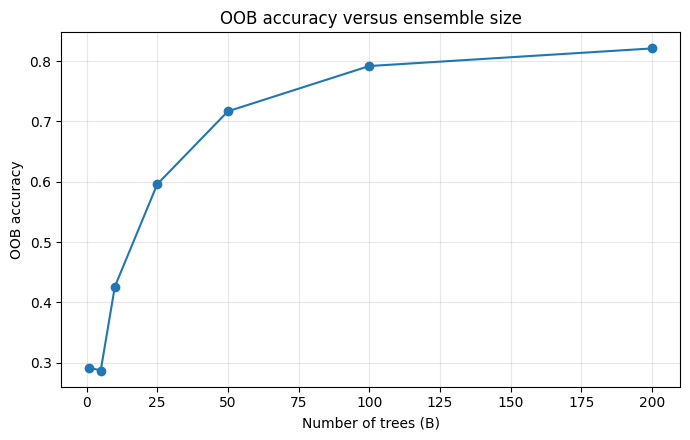

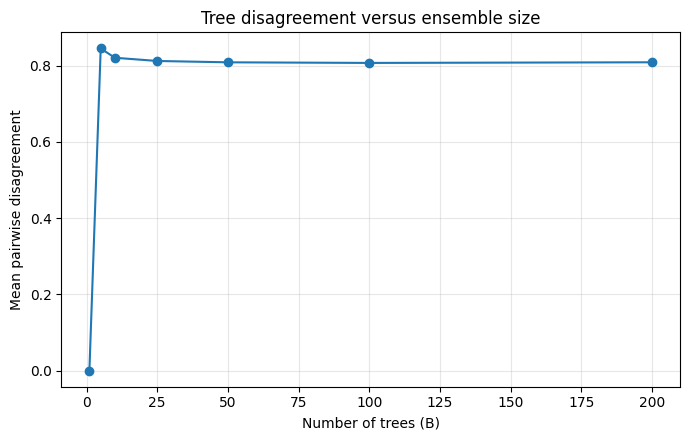

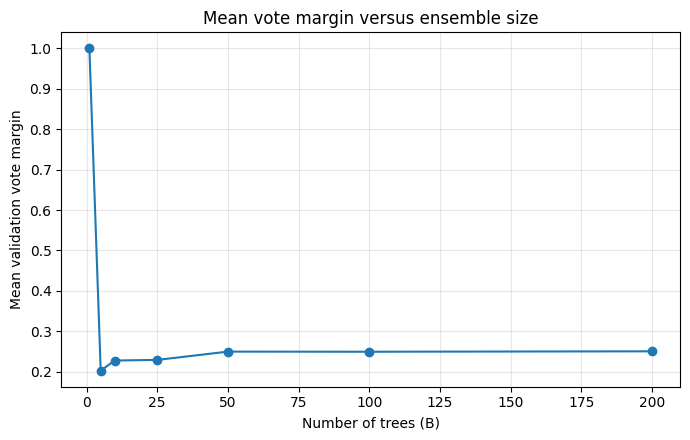

,B,validation_accuracy,oob_accuracy,mean_pairwise_disagreement,mean_validation_vote_margin
0,1,0.3000,0.292135,0.000000,1.00000
1,5,0.4500,0.287037,0.845000,0.20250
2,10,0.6625,0.426160,0.820556,0.22750
3,25,0.7250,0.595833,0.812125,0.22900
4,50,0.7625,0.716667,0.808602,0.24950
5,100,0.8000,0.791667,0.807008,0.24925
6,200,0.8250,0.820833,0.808690,0.25025


Selected final ensemble size (validation accuracy only): 200


In [5]:
# Plot 1: OOB accuracy
plt.figure(figsize=(7, 4.5))
plt.plot(oob_metrics["B"], oob_metrics["oob_accuracy"], marker="o")
plt.xlabel("Number of trees (B)")
plt.ylabel("OOB accuracy")
plt.title("OOB accuracy versus ensemble size")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "q1c_oob_accuracy.png"), dpi=160)
plt.show()

# Plot 2: average pairwise disagreement
plt.figure(figsize=(7, 4.5))
plt.plot(disagreement_metrics["B"], disagreement_metrics["mean_pairwise_disagreement"], marker="o")
plt.xlabel("Number of trees (B)")
plt.ylabel("Mean pairwise disagreement")
plt.title("Tree disagreement versus ensemble size")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "q1c_pairwise_disagreement.png"), dpi=160)
plt.show()

# Plot 3: mean validation vote margin
plt.figure(figsize=(7, 4.5))
plt.plot(margin_metrics["B"], margin_metrics["mean_validation_vote_margin"], marker="o")
plt.xlabel("Number of trees (B)")
plt.ylabel("Mean validation vote margin")
plt.title("Mean vote margin versus ensemble size")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "q1c_vote_margin.png"), dpi=160)
plt.show()

diagnostics = (
    bagging_metrics[["B", "validation_accuracy"]]
    .merge(oob_metrics[["B", "oob_accuracy"]], on="B")
    .merge(disagreement_metrics, on="B")
    .merge(margin_metrics, on="B")
)
display(diagnostics)
diagnostics.to_csv(os.path.join(OUT_DIR, "q1c_combined_diagnostics.csv"), index=False)

# Select final B using validation accuracy only; ties prefer the smaller B.
max_val_acc = bagging_metrics["validation_accuracy"].max()
FINAL_B = int(bagging_metrics.loc[
    bagging_metrics["validation_accuracy"] == max_val_acc, "B"
].min())
print("Selected final ensemble size (validation accuracy only):", FINAL_B)


### How to discuss whether the diagnostics agree

Use the plotted values and table. Validation accuracy is the selection criterion. OOB accuracy is an additional generalisation estimate, disagreement describes how differently trees predict, and vote margin measures how decisive the aggregate vote is. These quantities need not move together: disagreement can remain high even when majority voting is accurate, and a larger margin is not a guarantee of correctness.

## 5. Q1(d): clean versus masked test set

Compare the frozen single tree with the final bagged model. For the tree, confidence is the maximum class probability from `predict_proba`. For bagging, confidence is the winning fraction of tree votes. The masked test set has the centred 16×16 patch set to zero; no model is retrained on masked images.

In [6]:
final_bag = bag_trees[:FINAL_B]

def tree_predict_confidence(model, X_eval):
    pred = model.predict(X_eval)
    probs = model.predict_proba(X_eval)
    confidence = probs.max(axis=1)
    return pred, confidence

def bag_predict_confidence(models, X_eval):
    votes = vote_matrix(models, X_eval, classes)
    pred, confidence, margin = summarize_votes(votes, classes)
    return pred, confidence, margin, votes

tree_clean_pred, tree_clean_conf = tree_predict_confidence(tree, X_test)
tree_mask_pred, tree_mask_conf = tree_predict_confidence(tree, X_test_masked)

bag_clean_pred, bag_clean_conf, bag_clean_margin, bag_clean_votes = bag_predict_confidence(final_bag, X_test)
bag_mask_pred, bag_mask_conf, bag_mask_margin, bag_mask_votes = bag_predict_confidence(final_bag, X_test_masked)

robustness_rows = [
    {
        "model": "Frozen single tree",
        "test_set": "clean",
        "accuracy": accuracy_score(y_test, tree_clean_pred),
        "mean_winning_confidence": float(np.mean(tree_clean_conf))
    },
    {
        "model": "Frozen single tree",
        "test_set": "masked",
        "accuracy": accuracy_score(y_test, tree_mask_pred),
        "mean_winning_confidence": float(np.mean(tree_mask_conf))
    },
    {
        "model": f"Bagging (B={FINAL_B})",
        "test_set": "clean",
        "accuracy": accuracy_score(y_test, bag_clean_pred),
        "mean_winning_confidence": float(np.mean(bag_clean_conf))
    },
    {
        "model": f"Bagging (B={FINAL_B})",
        "test_set": "masked",
        "accuracy": accuracy_score(y_test, bag_mask_pred),
        "mean_winning_confidence": float(np.mean(bag_mask_conf))
    }
]
robustness_df = pd.DataFrame(robustness_rows)
display(robustness_df)
robustness_df.to_csv(os.path.join(OUT_DIR, "q1d_clean_masked_metrics.csv"), index=False)

# Build a table linking each test image to true label, tree prediction, bagging prediction,
# confidences, and vote counts for both clean and masked inputs.
case_df = pd.DataFrame({
    "dataset_index": test_idx,
    "true_identity": y_test,
    "tree_clean_prediction": tree_clean_pred,
    "tree_clean_confidence": tree_clean_conf,
    "bag_clean_prediction": bag_clean_pred,
    "bag_clean_confidence": bag_clean_conf,
    "tree_masked_prediction": tree_mask_pred,
    "tree_masked_confidence": tree_mask_conf,
    "bag_masked_prediction": bag_mask_pred,
    "bag_masked_confidence": bag_mask_conf
})
case_df["tree_correct_clean"] = case_df["tree_clean_prediction"] == case_df["true_identity"]
case_df["bag_correct_clean"] = case_df["bag_clean_prediction"] == case_df["true_identity"]
case_df["tree_correct_masked"] = case_df["tree_masked_prediction"] == case_df["true_identity"]
case_df["bag_correct_masked"] = case_df["bag_masked_prediction"] == case_df["true_identity"]
case_df.to_csv(os.path.join(OUT_DIR, "q1d_test_case_predictions.csv"), index=False)

# Two cases where bagging corrects the tree on the clean test set.
corrected = case_df[
    (~case_df["tree_correct_clean"]) & (case_df["bag_correct_clean"])
].head(2)

# Two cases where both are wrong on the clean test set.
both_wrong = case_df[
    (~case_df["tree_correct_clean"]) & (~case_df["bag_correct_clean"])
].head(2)

def vote_counts_for_dataset_index(dataset_index, masked=False):
    row_pos = int(np.flatnonzero(test_idx == dataset_index)[0])
    votes = bag_mask_votes[row_pos] if masked else bag_clean_votes[row_pos]
    return {int(classes[i]): int(votes[i]) for i in range(len(classes)) if votes[i] > 0}

def show_cases(df, title, masked=False):
    print("\n" + title)
    if len(df) == 0:
        print("No cases found in this run.")
        return
    for _, row in df.iterrows():
        idx = int(row["dataset_index"])
        print({
            "dataset_index": idx,
            "true_identity": int(row["true_identity"]),
            "tree_prediction": int(row["tree_masked_prediction"] if masked else row["tree_clean_prediction"]),
            "tree_confidence": float(row["tree_masked_confidence"] if masked else row["tree_clean_confidence"]),
            "bagging_prediction": int(row["bag_masked_prediction"] if masked else row["bag_clean_prediction"]),
            "bagging_confidence": float(row["bag_masked_confidence"] if masked else row["bag_clean_confidence"]),
            "bagging_vote_counts_by_identity": vote_counts_for_dataset_index(idx, masked=masked)
        })

show_cases(corrected, "Two clean test cases where bagging corrects the tree")
show_cases(both_wrong, "Two clean test cases where both models are wrong")

# Also save the selected examples and their vote counts to JSON for reproducibility.
case_details = {"bagging_corrects_tree_clean": [], "both_wrong_clean": []}
for key, df in [("bagging_corrects_tree_clean", corrected), ("both_wrong_clean", both_wrong)]:
    for _, row in df.iterrows():
        idx = int(row["dataset_index"])
        case_details[key].append({
            "dataset_index": idx,
            "true_identity": int(row["true_identity"]),
            "tree_prediction": int(row["tree_clean_prediction"]),
            "bagging_prediction": int(row["bag_clean_prediction"]),
            "bagging_vote_counts_by_identity": vote_counts_for_dataset_index(idx, masked=False)
        })
with open(os.path.join(OUT_DIR, "q1d_selected_cases.json"), "w", encoding="utf-8") as f:
    json.dump(case_details, f, indent=2)


,model,test_set,accuracy,mean_winning_confidence
0,Frozen single tree,clean,0.6625,1.000000
1,Frozen single tree,masked,0.2875,1.000000
2,Bagging (B=200),clean,0.9125,0.405625
3,Bagging (B=200),masked,0.7250,0.302125



Two clean test cases where bagging corrects the tree
{'dataset_index': 18, 'true_identity': 1, 'tree_prediction': 25, 'tree_confidence': 1.0, 'bagging_prediction': 1, 'bagging_confidence': 0.48, 'bagging_vote_counts_by_identity': {0: 1, 1: 96, 2: 3, 3: 12, 5: 2, 6: 13, 8: 1, 9: 2, 10: 2, 11: 1, 12: 6, 13: 1, 14: 4, 15: 3, 16: 1, 18: 1, 19: 2, 20: 1, 21: 1, 23: 2, 24: 1, 25: 2, 26: 4, 27: 2, 29: 1, 30: 15, 31: 2, 33: 11, 35: 1, 37: 1, 38: 3, 39: 2}}
{'dataset_index': 29, 'true_identity': 2, 'tree_prediction': 17, 'tree_confidence': 1.0, 'bagging_prediction': 2, 'bagging_confidence': 0.255, 'bagging_vote_counts_by_identity': {0: 3, 1: 2, 2: 51, 3: 13, 4: 6, 5: 6, 6: 3, 7: 1, 9: 9, 10: 4, 11: 3, 12: 13, 13: 4, 14: 2, 15: 5, 17: 25, 22: 3, 24: 4, 25: 3, 26: 1, 27: 15, 28: 1, 31: 5, 34: 4, 36: 1, 37: 8, 39: 5}}

Two clean test cases where both models are wrong
{'dataset_index': 61, 'true_identity': 6, 'tree_prediction': 1, 'tree_confidence': 1.0, 'bagging_prediction': 2, 'bagging_confidenc

## 6. Optional: display the selected faces

These visualizations are for interpreting the selected cases. The dataset index identifies the image in the original `fetch_olivetti_faces(shuffle=False)` ordering.

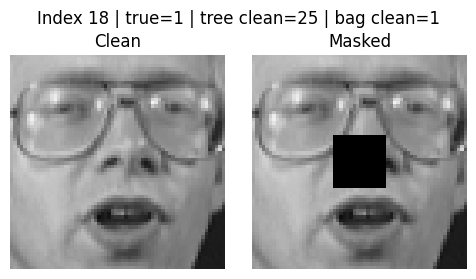

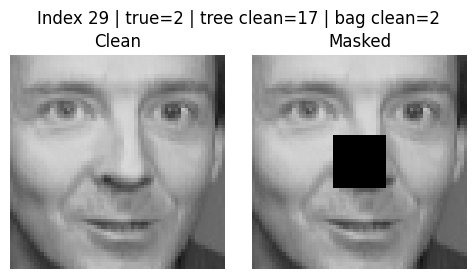

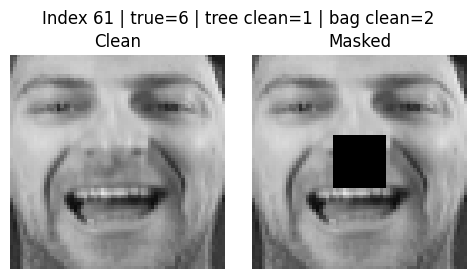

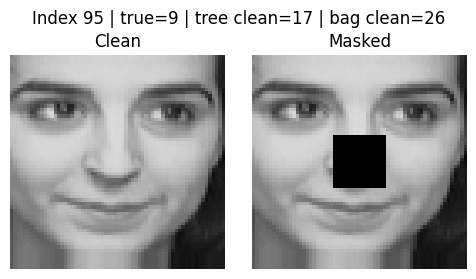

In [7]:
def plot_test_case(dataset_index):
    pos = int(np.flatnonzero(test_idx == dataset_index)[0])
    fig, axes = plt.subplots(1, 2, figsize=(5, 2.8))
    axes[0].imshow(X_images[dataset_index], cmap="gray", vmin=0, vmax=1)
    axes[0].set_title("Clean")
    axes[1].imshow(X_images_masked[dataset_index], cmap="gray", vmin=0, vmax=1)
    axes[1].set_title("Masked")
    for ax in axes:
        ax.axis("off")
    fig.suptitle(
        f"Index {dataset_index} | true={int(y[dataset_index])} | "
        f"tree clean={int(tree_clean_pred[pos])} | bag clean={int(bag_clean_pred[pos])}"
    )
    plt.tight_layout()
    plt.show()

example_indices = list(corrected["dataset_index"].astype(int)) + list(both_wrong["dataset_index"].astype(int))
for idx in example_indices:
    plot_test_case(idx)


## 7. Save a compact Q1 results summary

This cell saves the frozen configuration, final ensemble size, and principal metrics. It also prints the list of files created. Keep the split file and all output files with the notebook for reproducibility.

In [8]:
summary = {
    "roll_number": ROLL_NUMBER,
    "seed": SEED,
    "split_file": os.path.basename(split_path),
    "selected_tree": {
        "max_depth": BEST_DEPTH if BEST_DEPTH is not None else "None",
        "min_samples_leaf": BEST_MIN_LEAF,
        **{k: float(v) for k, v in baseline_metrics.items()},
        **{k: float(v) for k, v in baseline_leaf_stats.items()}
    },
    "final_bagging_B": FINAL_B,
    "bagging_at_final_B": bagging_metrics.loc[bagging_metrics["B"] == FINAL_B].iloc[0].to_dict(),
    "oob_at_final_B": oob_metrics.loc[oob_metrics["B"] == FINAL_B].iloc[0].to_dict(),
    "disagreement_at_final_B": disagreement_metrics.loc[disagreement_metrics["B"] == FINAL_B].iloc[0].to_dict(),
    "vote_margin_at_final_B": margin_metrics.loc[margin_metrics["B"] == FINAL_B].iloc[0].to_dict(),
    "robustness": robustness_rows
}
with open(os.path.join(OUT_DIR, "q1_results_summary.json"), "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, default=lambda x: float(x) if isinstance(x, (np.floating,)) else int(x) if isinstance(x, (np.integer,)) else str(x))

print("Saved outputs:")
for name in sorted(os.listdir(OUT_DIR)):
    print(" -", name)


Saved outputs:
 - olivetti_split_seed_242007.npz
 - q1_results_summary.json
 - q1a_selected_tree_metrics.csv
 - q1a_tree_grid.csv
 - q1b_bagging_metrics.csv
 - q1c_combined_diagnostics.csv
 - q1c_disagreement_metrics.csv
 - q1c_oob_accuracy.png
 - q1c_oob_metrics.csv
 - q1c_pairwise_disagreement.png
 - q1c_vote_margin.png
 - q1c_vote_margin_metrics.csv
 - q1d_clean_masked_metrics.csv
 - q1d_selected_cases.json
 - q1d_test_case_predictions.csv
 - split_metadata.json


## 8. Reporting checklist for Q1

Before writing the report, verify that your actual run contains:

- **Q1(a):** the full 15-setting grid, frozen validation-selected configuration, train/validation/test accuracy, leaves, mean training samples per leaf, and singleton-leaf fraction.
- **Q1(b):** results for all seven values of `B`, measured distinct bootstrap examples, and theoretical expectation.
- **Q1(c):** OOB accuracy, pairwise disagreement, vote margin plots, final `B` selected using validation accuracy, and a discussion grounded in the measured trends.
- **Q1(d):** clean and masked test accuracy/confidence for both models; two tree-error cases corrected by bagging and two cases where both are wrong, including vote counts.
- **Reproducibility:** retain this notebook, the saved split `.npz`, metadata, CSV logs, plots, JSON summary, package versions, and your exact run environment.

Do not invent missing cases or numerical values. If fewer than two cases of a requested type exist in this run, report that honestly rather than fabricating examples.